# Supervised Learning



## 1. Import Libraries & Load Data

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut, TimeSeriesSplit
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

In [ ]:
data_path = Path('../data/final')

X_train = pd.read_csv(data_path / 'X_train.csv')
X_val = pd.read_csv(data_path / 'X_val.csv')
X_test = pd.read_csv(data_path / 'X_test.csv')

y_train = pd.read_csv(data_path / 'y_train.csv')
y_val = pd.read_csv(data_path / 'y_val.csv')
y_test = pd.read_csv(data_path / 'y_test.csv')

m_train = pd.read_csv(data_path / 'meta_train.csv')
m_val = pd.read_csv(data_path / 'meta_val.csv')
m_test = pd.read_csv(data_path / 'meta_test.csv')

# Combine training and validation data for model development.
X_dev = pd.concat([X_train, X_val], ignore_index=True)
y_dev = pd.concat([y_train, y_val], ignore_index=True)
meta_dev = pd.concat([m_train, m_val], ignore_index=True)

feature_columns = [col for col in X_dev.columns if col != 'Region_le']
X_dev = X_dev[feature_columns].copy()
X_test_final = X_test[feature_columns].copy()
y_dev_array = y_dev['O3_AQI'].to_numpy()
y_test_final = y_test['O3_AQI'].to_numpy()

assert list(X_dev.columns) == list(X_test_final.columns), (
    'Training and test feature columns do not match.'
)
assert len(X_dev) == len(y_dev_array) == len(meta_dev)
assert len(X_test_final) == len(y_test_final) == len(m_test)

print('Development data:', X_dev.shape)
print('Test data:', X_test_final.shape)
print('Metadata columns:', meta_dev.columns.tolist())

Development data: (56857, 24)
Test data: (11134, 24)
Metadata columns: ['station', 'Date Local', 'State', 'Region']


## 2. Random Forest — Spatial Blocking



In [ ]:
def get_station_groups(metadata):
    normalized = {str(col).strip().lower().replace('_', ' ').replace('-', ' '): col
                  for col in metadata.columns}

    direct_candidates = [
        'station id', 'station', 'site id', 'monitoring station',
        'monitoring site', 'site'
    ]
    for candidate in direct_candidates:
        if candidate in normalized:
            return metadata[normalized[candidate]].astype(str).to_numpy(), normalized[candidate]

    component_sets = [
        ('state code', 'county code', 'site num'),
        ('state code', 'county code', 'site number'),
        ('state', 'county', 'site num'),
        ('state', 'county', 'site number')
    ]
    for components in component_sets:
        if all(name in normalized for name in components):
            cols = [normalized[name] for name in components]
            groups = metadata[cols].astype(str).agg('-'.join, axis=1).to_numpy()
            return groups, ' + '.join(cols)

    raise ValueError(
        'Could not identify a unique monitoring-station column in metadata. '
        'Available columns: ' + ', '.join(map(str, metadata.columns)) + '. '
        'Please provide a Station ID column or the State Code, County Code, '
        'and Site Num columns.'
    )

spatial_groups, station_source = get_station_groups(meta_dev)

X_spatial = X_dev.copy()
y_spatial = y_dev_array

print('X shape:', X_spatial.shape)
print('y shape:', y_spatial.shape)
print('Station identifier:', station_source)
print('Number of unique stations:', pd.Series(spatial_groups).nunique())

X shape: (56857, 24)
y shape: (56857,)
Station identifier: station
Number of unique stations: 37


In [4]:
logo = LeaveOneGroupOut()

spatial_results = []
spatial_predictions = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X_spatial, y_spatial, spatial_groups), start=1
):
    X_tr = X_spatial.iloc[train_idx]
    X_te = X_spatial.iloc[test_idx]
    y_tr = y_spatial[train_idx]
    y_te = y_spatial[test_idx]

    rf_model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        max_features=0.5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    rf_model.fit(X_tr, y_tr)
    y_pred = rf_model.predict(X_te)

    station = spatial_groups[test_idx][0]
    spatial_results.append({
        'Station': station,
        'RMSE': np.sqrt(mean_squared_error(y_te, y_pred)),
        'MAE': mean_absolute_error(y_te, y_pred),
        'R2': r2_score(y_te, y_pred)
    })
    spatial_predictions.extend(zip([station] * len(y_te), y_te, y_pred))

spatial_results = pd.DataFrame(spatial_results)
print(spatial_results)

        Station       RMSE        MAE        R2
0       11_1_41  12.983884   8.325391  0.540735
1    12_95_2002  10.005725   6.716456  0.388016
2       13_89_2  13.050497   8.545276  0.463491
3     17_163_10  12.694423   8.270962  0.522793
4     19_163_15   7.998885   5.711815  0.566721
5     20_209_21   9.953831   6.812325  0.551097
6       22_33_9  13.181985   8.905866  0.329757
7     23_3_1100   5.745199   4.302792  0.363733
8       23_5_29   8.147862   5.619283  0.295332
9     24_5_3001  13.720935   8.512001  0.518196
10     25_25_42   7.715125   5.566896  0.351127
11     32_31_16   9.800695   6.876915  0.667074
12      34_13_3  12.988890   8.588637  0.451832
13      35_1_23   8.692175   6.116499  0.660662
14     36_5_133  11.487595   7.377563  0.508681
15    36_81_124  11.615352   7.304409  0.520835
16    37_119_41  13.078193   8.687711  0.505106
17   38_17_1004   6.114653   4.485290  0.605482
18     39_35_60  10.027145   6.957421  0.439182
19  40_109_1037  15.476094  10.223628  0

In [5]:
print('Average Spatial Blocking Results (station-level folds)')
print('Mean RMSE:', spatial_results['RMSE'].mean())
print('Mean MAE:', spatial_results['MAE'].mean())
print('Mean R2:', spatial_results['R2'].mean())

Average Spatial Blocking Results (station-level folds)
Mean RMSE: 10.9163504965863
Mean MAE: 7.268368804385135
Mean R2: 0.49037123185903403


In [6]:
feature_importances = []

for train_idx, test_idx in logo.split(X_spatial, y_spatial, spatial_groups):
    rf_model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        max_features=0.5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    rf_model.fit(X_spatial.iloc[train_idx], y_spatial[train_idx])
    feature_importances.append(rf_model.feature_importances_)

importance_df = pd.DataFrame({
    'Feature': X_spatial.columns,
    'Importance': np.mean(feature_importances, axis=0)
}).sort_values(by='Importance', ascending=False)

print(importance_df)

           Feature  Importance
0      O3_AQI_lag1    0.398661
3    O3_roll_mean7    0.220206
1      O3_AQI_lag7    0.068089
4     O3_roll_std7    0.040149
2     O3_AQI_lag30    0.029881
5     NO2_AQI_lag1    0.022926
9    NO2_roll_std7    0.022548
8   NO2_roll_mean7    0.020119
14   SO2_roll_std7    0.016927
7    NO2_AQI_lag30    0.016693
21           Month    0.016566
6     NO2_AQI_lag7    0.015963
18   CO_roll_mean7    0.015606
19    CO_roll_std7    0.015459
13  SO2_roll_mean7    0.015129
10    SO2_AQI_lag1    0.009727
23       Season_le    0.009501
12   SO2_AQI_lag30    0.008351
11    SO2_AQI_lag7    0.008235
17    CO_AQI_lag30    0.007621
20            Year    0.007459
15     CO_AQI_lag1    0.006959
16     CO_AQI_lag7    0.006707
22    area_type_le    0.000516


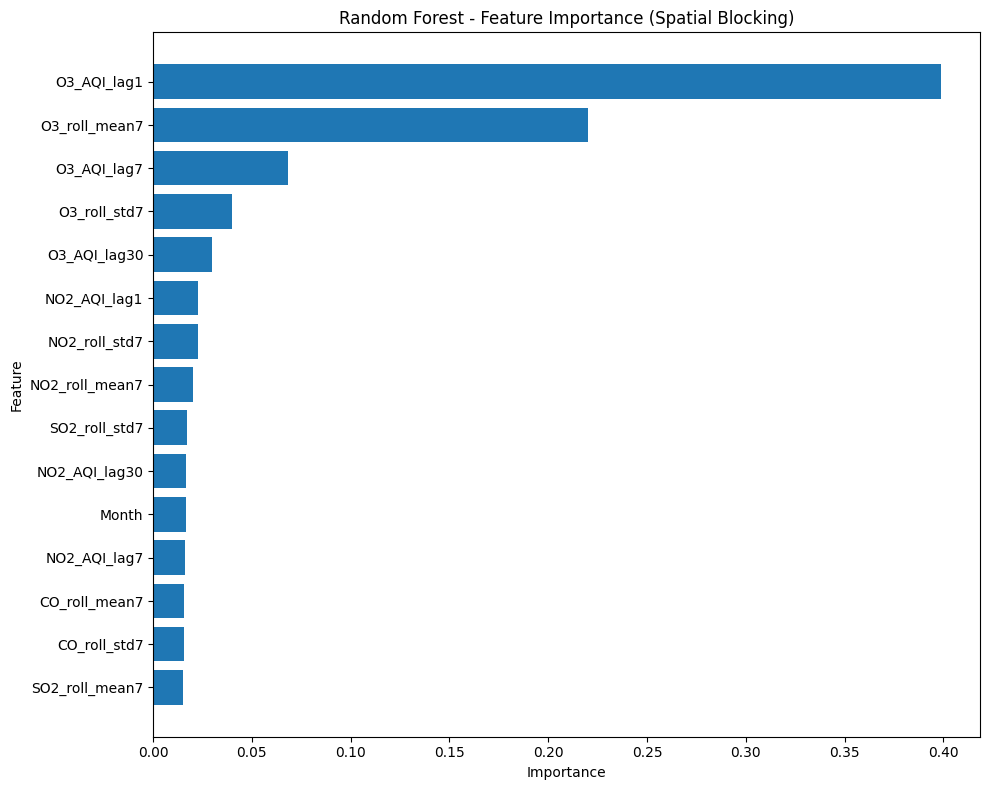

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.barh(
    importance_df['Feature'].head(15)[::-1],
    importance_df['Importance'].head(15)[::-1]
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Random Forest - Feature Importance (Spatial Blocking)')
plt.tight_layout()
plt.show()

## 3. XGBoost — Temporal Cross-Validation



In [8]:
X_xgb = X_dev.copy()
y_xgb = y_dev_array.copy()
dates_xgb = pd.to_datetime(meta_dev['Date Local'], errors='coerce')

valid_date_mask = dates_xgb.notna().to_numpy()
X_xgb = X_xgb.loc[valid_date_mask].reset_index(drop=True)
y_xgb = y_xgb[valid_date_mask]
dates_xgb = dates_xgb.loc[valid_date_mask].reset_index(drop=True)

print('X shape:', X_xgb.shape)
print('y shape:', y_xgb.shape)
print('Dates shape:', dates_xgb.shape)
print('Number of unique dates:', dates_xgb.nunique())

X shape: (56857, 24)
y shape: (56857,)
Dates shape: (56857,)
Number of unique dates: 1796


In [9]:
unique_dates_xgb = np.sort(dates_xgb.unique())
tscv_xgb = TimeSeriesSplit(n_splits=5)
xgb_results = []

for fold, (train_date_idx, test_date_idx) in enumerate(
    tscv_xgb.split(unique_dates_xgb), start=1
):
    train_dates = unique_dates_xgb[train_date_idx]
    test_dates = unique_dates_xgb[test_date_idx]
    train_mask = dates_xgb.isin(train_dates).to_numpy()
    test_mask = dates_xgb.isin(test_dates).to_numpy()

    X_tr, X_te = X_xgb.loc[train_mask], X_xgb.loc[test_mask]
    y_tr, y_te = y_xgb[train_mask], y_xgb[test_mask]

    print(f'Fold {fold}')
    print('Training dates:', train_dates[0], 'to', train_dates[-1])
    print('Testing dates:', test_dates[0], 'to', test_dates[-1])
    print('Training shape:', X_tr.shape)
    print('Testing shape:', X_te.shape)
    print('-' * 40)

Fold 1
Training dates: 2010-01-31T00:00:00.000000000 to 2010-11-27T00:00:00.000000000
Testing dates: 2010-11-28T00:00:00.000000000 to 2011-09-22T00:00:00.000000000
Training shape: (7275, 24)
Testing shape: (9494, 24)
----------------------------------------
Fold 2
Training dates: 2010-01-31T00:00:00.000000000 to 2011-09-22T00:00:00.000000000
Testing dates: 2011-09-23T00:00:00.000000000 to 2012-07-17T00:00:00.000000000
Training shape: (16769, 24)
Testing shape: (10057, 24)
----------------------------------------
Fold 3
Training dates: 2010-01-31T00:00:00.000000000 to 2012-07-17T00:00:00.000000000
Testing dates: 2012-07-18T00:00:00.000000000 to 2013-05-12T00:00:00.000000000
Training shape: (26826, 24)
Testing shape: (10420, 24)
----------------------------------------
Fold 4
Training dates: 2010-01-31T00:00:00.000000000 to 2013-05-12T00:00:00.000000000
Testing dates: 2013-05-13T00:00:00.000000000 to 2014-03-07T00:00:00.000000000
Training shape: (37246, 24)
Testing shape: (9856, 24)
----

In [10]:
for fold, (train_date_idx, test_date_idx) in enumerate(
    tscv_xgb.split(unique_dates_xgb), start=1
):
    train_dates = unique_dates_xgb[train_date_idx]
    test_dates = unique_dates_xgb[test_date_idx]
    train_mask = dates_xgb.isin(train_dates).to_numpy()
    test_mask = dates_xgb.isin(test_dates).to_numpy()

    X_tr, X_te = X_xgb.loc[train_mask], X_xgb.loc[test_mask]
    y_tr, y_te = y_xgb[train_mask], y_xgb[test_mask]

    xgb_model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    xgb_model.fit(X_tr, y_tr)
    y_pred = xgb_model.predict(X_te)

    xgb_results.append({
        'Fold': fold,
        'RMSE': np.sqrt(mean_squared_error(y_te, y_pred)),
        'MAE': mean_absolute_error(y_te, y_pred),
        'R2': r2_score(y_te, y_pred)
    })

xgb_results = pd.DataFrame(xgb_results)
print(xgb_results)

   Fold       RMSE       MAE        R2
0     1  12.532370  7.860567  0.486563
1     2  10.802545  6.734597  0.595134
2     3  10.043721  6.661362  0.570181
3     4  11.446143  7.389601  0.573734
4     5  11.595125  7.872777  0.497137


In [11]:
print('XGBoost - Temporal Cross-Validation Results')
print('Mean RMSE:', xgb_results['RMSE'].mean())
print('Mean MAE:', xgb_results['MAE'].mean())
print('Mean R2:', xgb_results['R2'].mean())

XGBoost - Temporal Cross-Validation Results
Mean RMSE: 11.28398095453708
Mean MAE: 7.30378090690957
Mean R2: 0.5445498941774765


In [12]:
xgb_feature_importances = []

for train_date_idx, test_date_idx in tscv_xgb.split(unique_dates_xgb):
    train_dates = unique_dates_xgb[train_date_idx]
    train_mask = dates_xgb.isin(train_dates).to_numpy()
    X_tr = X_xgb.loc[train_mask]
    y_tr = y_xgb[train_mask]

    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    xgb_feature_importances.append(model.feature_importances_)

xgb_importance_df = pd.DataFrame({
    'Feature': X_xgb.columns,
    'Importance': np.mean(xgb_feature_importances, axis=0)
}).sort_values(by='Importance', ascending=False)

print(xgb_importance_df)

           Feature  Importance
0      O3_AQI_lag1    0.271560
3    O3_roll_mean7    0.142155
23       Season_le    0.061404
1      O3_AQI_lag7    0.040217
5     NO2_AQI_lag1    0.036546
21           Month    0.033698
4     O3_roll_std7    0.029101
8   NO2_roll_mean7    0.026345
18   CO_roll_mean7    0.025782
13  SO2_roll_mean7    0.025128
14   SO2_roll_std7    0.024154
10    SO2_AQI_lag1    0.023884
2     O3_AQI_lag30    0.023708
11    SO2_AQI_lag7    0.023417
9    NO2_roll_std7    0.022762
19    CO_roll_std7    0.022742
17    CO_AQI_lag30    0.022388
6     NO2_AQI_lag7    0.022209
7    NO2_AQI_lag30    0.021810
16     CO_AQI_lag7    0.021401
20            Year    0.020547
15     CO_AQI_lag1    0.020383
12   SO2_AQI_lag30    0.019784
22    area_type_le    0.018875


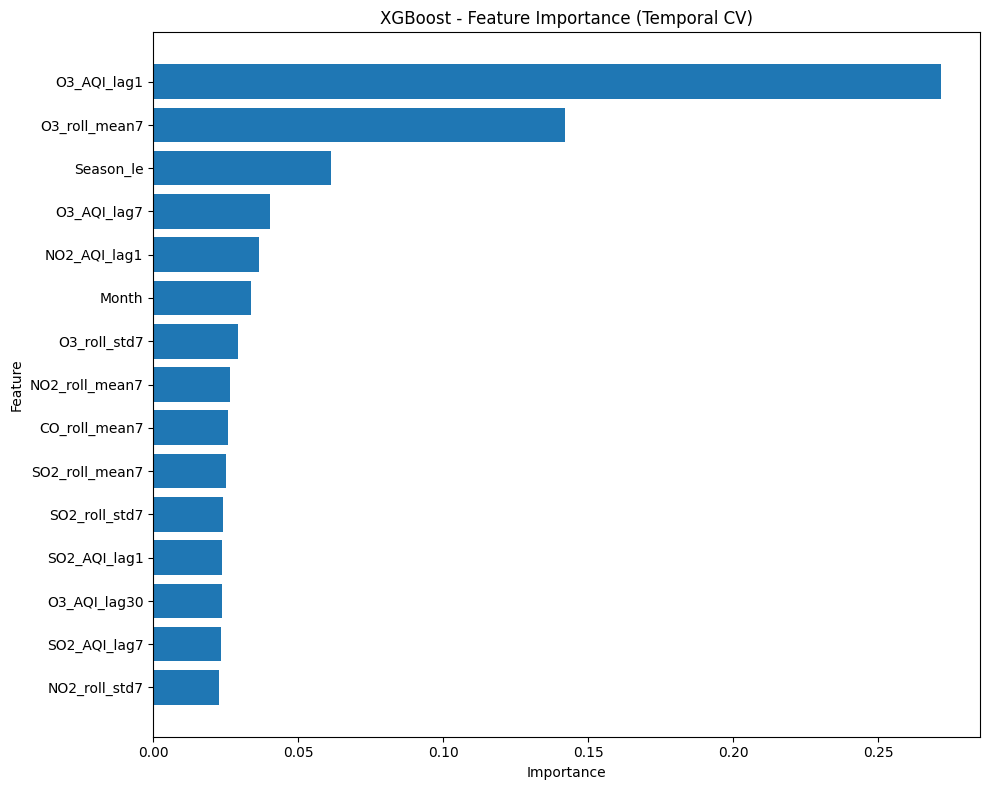

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

top_features = xgb_importance_df.head(15)

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('XGBoost - Feature Importance (Temporal CV)')
plt.tight_layout()
plt.show()

## 4. Gradient Boosting — Temporal Cross-Validation

In [14]:
X_gb = X_dev.loc[valid_date_mask].reset_index(drop=True)
y_gb = y_dev_array[valid_date_mask]
dates_gb = dates_xgb.copy()

unique_dates_gb = np.sort(dates_gb.unique())
tscv_gb = TimeSeriesSplit(n_splits=5)

print('X shape:', X_gb.shape)
print('y shape:', y_gb.shape)
print('Number of unique dates:', len(unique_dates_gb))

X shape: (56857, 24)
y shape: (56857,)
Number of unique dates: 1796


In [15]:
gb_results = []

for fold, (train_idx, test_idx) in enumerate(
    tscv_gb.split(unique_dates_gb), start=1
):
    train_dates = unique_dates_gb[train_idx]
    test_dates = unique_dates_gb[test_idx]
    train_mask = dates_gb.isin(train_dates).to_numpy()
    test_mask = dates_gb.isin(test_dates).to_numpy()

    X_tr, X_te = X_gb.loc[train_mask], X_gb.loc[test_mask]
    y_tr, y_te = y_gb[train_mask], y_gb[test_mask]

    gb_model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=RANDOM_STATE
    )
    gb_model.fit(X_tr, y_tr)
    y_pred = gb_model.predict(X_te)

    gb_results.append({
        'Fold': fold,
        'RMSE': np.sqrt(mean_squared_error(y_te, y_pred)),
        'MAE': mean_absolute_error(y_te, y_pred),
        'R2': r2_score(y_te, y_pred)
    })
    print(f'Fold {fold} completed')

gb_results = pd.DataFrame(gb_results)
print(gb_results)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
   Fold       RMSE       MAE        R2
0     1  12.298485  7.675988  0.505548
1     2  10.693721  6.685965  0.603251
2     3   9.952915  6.581948  0.577918
3     4  11.323063  7.354060  0.582852
4     5  11.617267  7.898510  0.495214


In [16]:
print('Gradient Boosting - Temporal CV')
print('Mean RMSE:', gb_results['RMSE'].mean())
print('Mean MAE:', gb_results['MAE'].mean())
print('Mean R2:', gb_results['R2'].mean())

Gradient Boosting - Temporal CV
Mean RMSE: 11.177090140024577
Mean MAE: 7.239294037911954
Mean R2: 0.5529566652605362


In [17]:
gb_feature_importances = []

for train_idx, test_idx in tscv_gb.split(unique_dates_gb):
    train_dates = unique_dates_gb[train_idx]
    train_mask = dates_gb.isin(train_dates).to_numpy()
    X_tr = X_gb.loc[train_mask]
    y_tr = y_gb[train_mask]

    model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=RANDOM_STATE
    )
    model.fit(X_tr, y_tr)
    gb_feature_importances.append(model.feature_importances_)

gb_importance_df = pd.DataFrame({
    'Feature': X_gb.columns,
    'Importance': np.mean(gb_feature_importances, axis=0)
}).sort_values(by='Importance', ascending=False)

print(gb_importance_df)

           Feature  Importance
0      O3_AQI_lag1    0.757321
3    O3_roll_mean7    0.137519
5     NO2_AQI_lag1    0.017060
1      O3_AQI_lag7    0.014836
4     O3_roll_std7    0.012681
2     O3_AQI_lag30    0.010515
23       Season_le    0.008567
21           Month    0.008485
6     NO2_AQI_lag7    0.004051
8   NO2_roll_mean7    0.004023
7    NO2_AQI_lag30    0.003342
11    SO2_AQI_lag7    0.002840
13  SO2_roll_mean7    0.002630
18   CO_roll_mean7    0.002550
9    NO2_roll_std7    0.002537
14   SO2_roll_std7    0.002371
10    SO2_AQI_lag1    0.002210
19    CO_roll_std7    0.001920
15     CO_AQI_lag1    0.001320
12   SO2_AQI_lag30    0.001301
17    CO_AQI_lag30    0.000795
16     CO_AQI_lag7    0.000634
20            Year    0.000290
22    area_type_le    0.000202


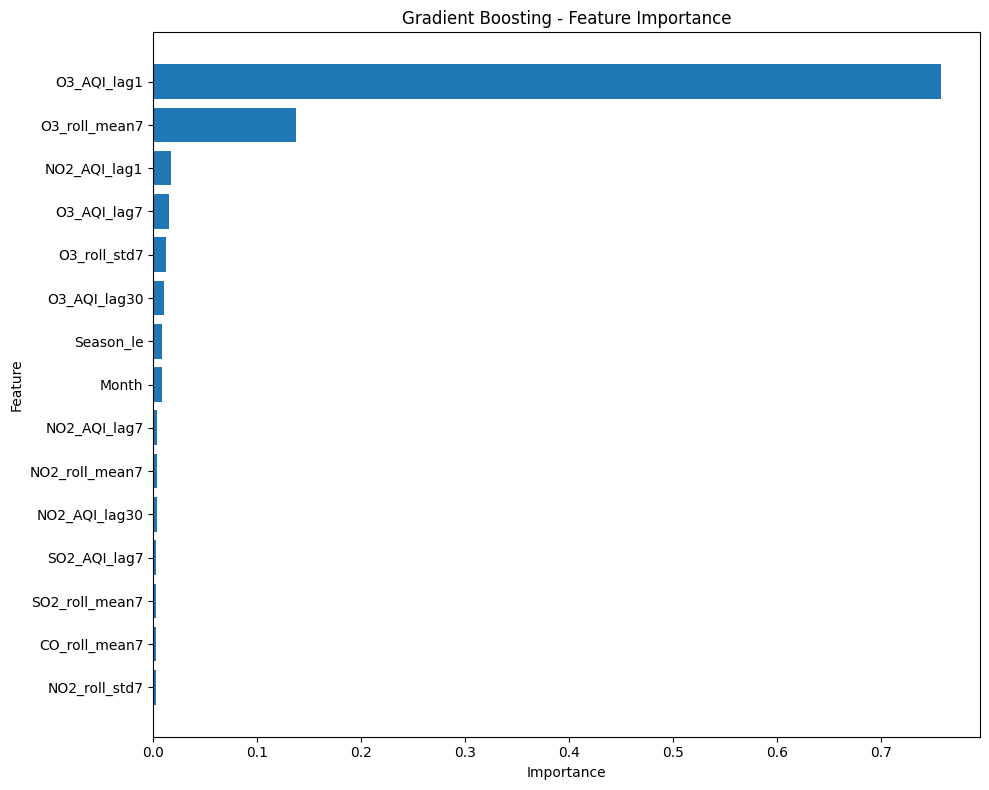

In [18]:
plt.figure(figsize=(10, 8))

top_features = gb_importance_df.head(15)

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Gradient Boosting - Feature Importance')
plt.tight_layout()
plt.show()

## 5. Model Comparison



In [19]:
model_comparison = pd.DataFrame([
    {
        'Model': 'Random Forest',
        'Validation Strategy': 'Spatial Blocking (station-level)',
        'RMSE': spatial_results['RMSE'].mean(),
        'MAE': spatial_results['MAE'].mean(),
        'R2': spatial_results['R2'].mean()
    },
    {
        'Model': 'XGBoost',
        'Validation Strategy': 'Temporal CV',
        'RMSE': xgb_results['RMSE'].mean(),
        'MAE': xgb_results['MAE'].mean(),
        'R2': xgb_results['R2'].mean()
    },
    {
        'Model': 'Gradient Boosting',
        'Validation Strategy': 'Temporal CV',
        'RMSE': gb_results['RMSE'].mean(),
        'MAE': gb_results['MAE'].mean(),
        'R2': gb_results['R2'].mean()
    }
])

print('CV results (different validation strategies; not directly comparable):')
display(model_comparison.round(4))

CV results (different validation strategies; not directly comparable):


,Model,Validation Strategy,RMSE,MAE,R2
0,Random Forest,Spatial Blocking (station-level),10.9164,7.2684,0.4904
1,XGBoost,Temporal CV,11.2840,7.3038,0.5445
2,Gradient Boosting,Temporal CV,11.1771,7.2393,0.5530


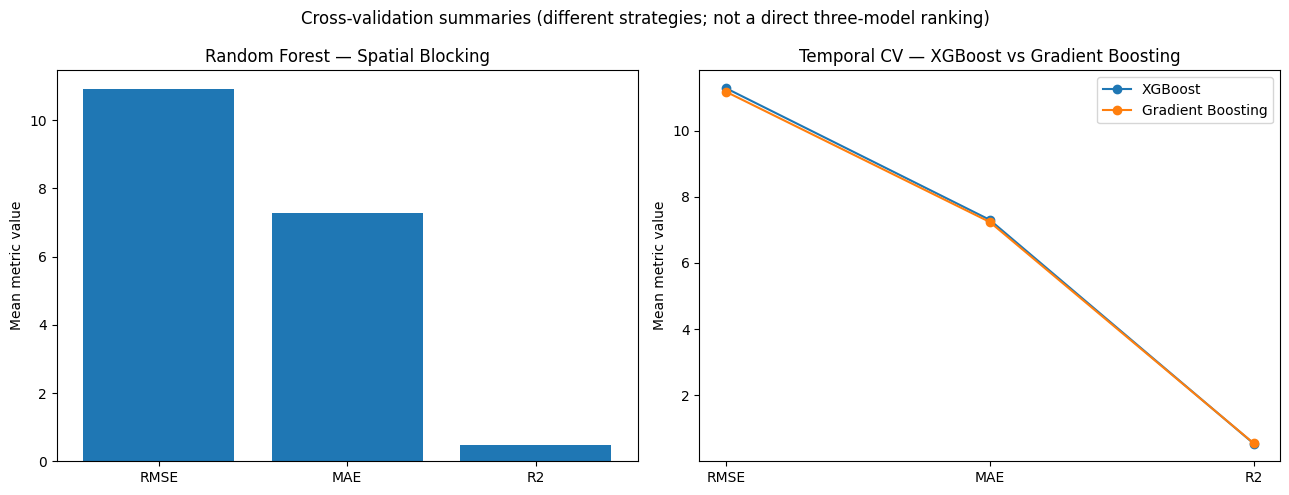

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

spatial_values = spatial_results[['RMSE', 'MAE', 'R2']].mean()
temporal_values = pd.DataFrame({
    'XGBoost': xgb_results[['RMSE', 'MAE', 'R2']].mean(),
    'Gradient Boosting': gb_results[['RMSE', 'MAE', 'R2']].mean()
})

axes[0].bar(spatial_values.index, spatial_values.values)
axes[0].set_title('Random Forest — Spatial Blocking')
axes[0].set_ylabel('Mean metric value')

for model_name, row in temporal_values.T.iterrows():
    axes[1].plot(row.index, row.values, marker='o', label=model_name)
axes[1].set_title('Temporal CV — XGBoost vs Gradient Boosting')
axes[1].set_ylabel('Mean metric value')
axes[1].legend()

plt.suptitle('Cross-validation summaries (different strategies; not a direct three-model ranking)')
plt.tight_layout()
plt.show()

## 6. Feature Importance & Pollutant Analysis

Feature importance describes predictive contribution within each fitted model. It does not establish causality, identify actual emission sources, or quantify physical source contributions.

In [21]:
rf_imp = importance_df.rename(columns={'Importance': 'Random Forest'})
xgb_imp = xgb_importance_df.rename(columns={'Importance': 'XGBoost'})
gb_imp = gb_importance_df.rename(columns={'Importance': 'Gradient Boosting'})

importance_comparison = (
    rf_imp[['Feature', 'Random Forest']]
    .merge(xgb_imp[['Feature', 'XGBoost']], on='Feature')
    .merge(gb_imp[['Feature', 'Gradient Boosting']], on='Feature')
)

importance_comparison['Average Importance'] = importance_comparison[
    ['Random Forest', 'XGBoost', 'Gradient Boosting']
].mean(axis=1)

importance_comparison = importance_comparison.sort_values(
    by='Average Importance', ascending=False
)
print(importance_comparison)

           Feature  Random Forest   XGBoost  Gradient Boosting  \
0      O3_AQI_lag1       0.398661  0.271560           0.757321   
1    O3_roll_mean7       0.220206  0.142155           0.137519   
2      O3_AQI_lag7       0.068089  0.040217           0.014836   
3     O3_roll_std7       0.040149  0.029101           0.012681   
16       Season_le       0.009501  0.061404           0.008567   
5     NO2_AQI_lag1       0.022926  0.036546           0.017060   
4     O3_AQI_lag30       0.029881  0.023708           0.010515   
10           Month       0.016566  0.033698           0.008485   
7   NO2_roll_mean7       0.020119  0.026345           0.004023   
6    NO2_roll_std7       0.022548  0.022762           0.002537   
12   CO_roll_mean7       0.015606  0.025782           0.002550   
8    SO2_roll_std7       0.016927  0.024154           0.002371   
14  SO2_roll_mean7       0.015129  0.025128           0.002630   
11    NO2_AQI_lag7       0.015963  0.022209           0.004051   
9    NO2_A

,Random Forest,XGBoost,Gradient Boosting
Pollutant,,,
CO,0.052353,0.112696,0.007219
NO2,0.098249,0.129672,0.031014
O3,0.756987,0.506741,0.932871
SO2,0.058369,0.116366,0.011352


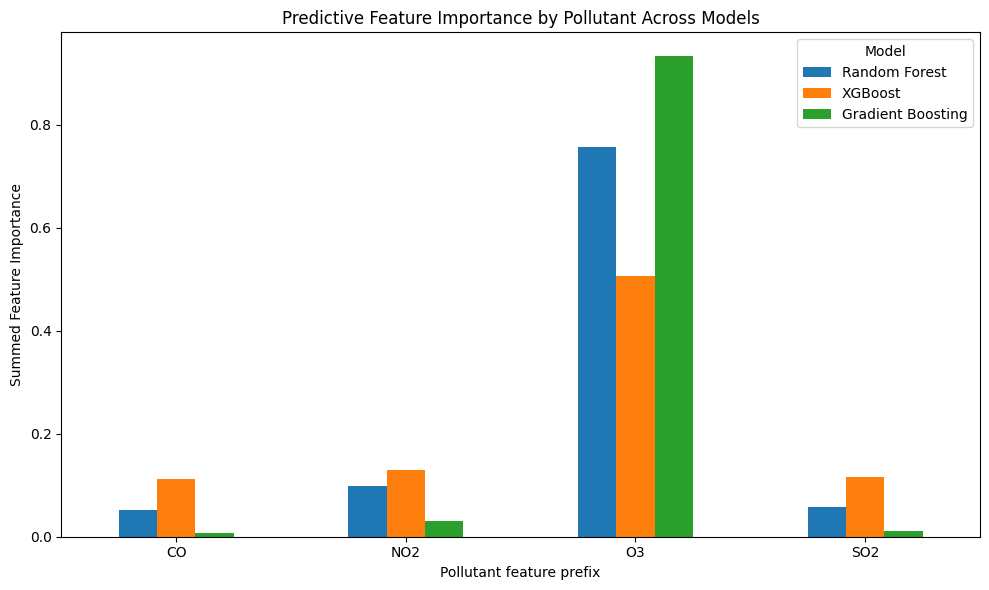

In [ ]:
# Aggregate feature importance by pollutant prefix (e.g. O3_AQI_lag1 -> O3).

pollutant_pattern = r'^(O3|NO2|SO2|CO)(?:_|$)'
importance_comparison['Pollutant'] = importance_comparison['Feature'].str.extract(
    pollutant_pattern, flags=re.IGNORECASE, expand=False
).str.upper()

pollutant_features = importance_comparison.dropna(subset=['Pollutant'])

if pollutant_features.empty:
    print('No pollutant-prefixed features matched the expected O3, NO2, SO2, or CO naming pattern.')
    print('Available feature names:', importance_comparison['Feature'].tolist())
else:
    pollution_attribution = (
        pollutant_features.groupby('Pollutant')[
            ['Random Forest', 'XGBoost', 'Gradient Boosting']
        ].sum().sort_index()
    )
    display(pollution_attribution)
    pollution_attribution.plot(kind='bar', figsize=(10, 6))
    plt.title('Predictive Feature Importance by Pollutant Across Models')
    plt.ylabel('Summed Feature Importance')
    plt.xlabel('Pollutant feature prefix')
    plt.xticks(rotation=0)
    plt.legend(title='Model')
    plt.tight_layout()
    plt.show()

## 7. Final Model Evaluation on the Held-Out Test Set (2015)


In [ ]:
# Final training uses training + validation data; 2015 remains held out.
y_train_final = y_dev_array

assert list(X_dev.columns) == list(X_test_final.columns)

# 1. Random Forest
rf_final = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    max_features=0.5,
    n_jobs=-1,
    random_state=RANDOM_STATE
)
rf_final.fit(X_dev, y_train_final)
rf_pred = rf_final.predict(X_test_final)

# 2. XGBoost
xgb_final = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgb_final.fit(X_dev, y_train_final)
xgb_pred = xgb_final.predict(X_test_final)

# 3. Gradient Boosting
gb_final = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=RANDOM_STATE
)
gb_final.fit(X_dev, y_train_final)
gb_pred = gb_final.predict(X_test_final)

predictions = {
    'Random Forest': rf_pred,
    'XGBoost': xgb_pred,
    'Gradient Boosting': gb_pred
}

test_results = pd.DataFrame([
    {
        'Model': model_name,
        'RMSE': np.sqrt(mean_squared_error(y_test_final, y_pred)),
        'MAE': mean_absolute_error(y_test_final, y_pred),
        'R2': r2_score(y_test_final, y_pred)
    }
    for model_name, y_pred in predictions.items()
])

print('Final Evaluation on Test Set (2015)')
display(test_results.round(4))
test_results.to_csv('../results/final_test_results_2015.csv', index=False)

Final Evaluation on Test Set (2015)


,Model,RMSE,MAE,R2
0,Random Forest,11.6202,7.5884,0.5407
1,XGBoost,11.6672,7.5629,0.5369
2,Gradient Boosting,11.6159,7.5707,0.5410


## 8. Final Model Comparison

In [25]:
cv_summary = pd.DataFrame([
    {
        'Model': 'Random Forest',
        'CV Strategy': 'Spatial Blocking (station-level)',
        'CV RMSE': spatial_results['RMSE'].mean(),
        'CV MAE': spatial_results['MAE'].mean(),
        'CV R2': spatial_results['R2'].mean()
    },
    {
        'Model': 'XGBoost',
        'CV Strategy': 'Temporal CV',
        'CV RMSE': xgb_results['RMSE'].mean(),
        'CV MAE': xgb_results['MAE'].mean(),
        'CV R2': xgb_results['R2'].mean()
    },
    {
        'Model': 'Gradient Boosting',
        'CV Strategy': 'Temporal CV',
        'CV RMSE': gb_results['RMSE'].mean(),
        'CV MAE': gb_results['MAE'].mean(),
        'CV R2': gb_results['R2'].mean()
    }
])

final_model_summary = cv_summary.merge(test_results, on='Model')
final_model_summary = final_model_summary.rename(columns={
    'RMSE': 'Test RMSE (2015)',
    'MAE': 'Test MAE (2015)',
    'R2': 'Test R2 (2015)'
})

display(final_model_summary.round(4))
final_model_summary.to_csv('../results/final_model_comparison.csv', index=False)

print('Note: CV metrics use different validation strategies. Compare models directly using the common 2015 test metrics.')

,Model,CV Strategy,CV RMSE,CV MAE,CV R2,Test RMSE (2015),Test MAE (2015),Test R2 (2015)
0,Random Forest,Spatial Blocking (station-level),10.9164,7.2684,0.4904,11.6202,7.5884,0.5407
1,XGBoost,Temporal CV,11.2840,7.3038,0.5445,11.6672,7.5629,0.5369
2,Gradient Boosting,Temporal CV,11.1771,7.2393,0.5530,11.6159,7.5707,0.5410


Note: CV metrics use different validation strategies. Compare models directly using the common 2015 test metrics.
